# Name That LLM Analyse, exécution et amélioration du notebook Kaggle

**Devoir d'élève ingénieur · Notebook unique pour Google Colab**  
**Source étudiée :** [lightningv08 — 0.681 | Qwen3-Embedding LoRA + Qwen3.8-27B](https://www.kaggle.com/code/lightningv08/0-681-qwen3-embedding-lora-qwen3-8-27b/notebook)  
**Chaîne attendue :** **DATA → EDA → PRÉTRAITEMENT → TRANSFORMATIONS → ML → EVAL → DEPLOY**

## Comment j'ai organisé mon travail

1. **J'analyse** les étapes du notebook original, sans prétendre que les phases absentes existent.
2. **Je tente l'exécution originale** dans Colab, j'en conserve les résultats *réellement obtenus* et je documente les limitations (notamment les poids externes).
3. **J'améliore** une branche existante de ce notebook pour couvrir explicitement toutes les étapes, avec une validation et une démonstration d'inférence.

> **Point de méthode :** le code original de lightningv08 figure **sans modification dans l'annexe exécutable**, à la fin. Cette annexe n'est **pas destinée à « Tout exécuter »** sur Colab sans télécharger les nombreux poids du modèle et disposer de ressources adaptées. J'explique à chaque étape les adaptations Colab et ce que j'ai effectivement testé.

# PARTIE 1  Audit du notebook original (avant toute modification)

J'ai inspecté les **50 cellules** du notebook initial (dont 39 cellules de code). Il s'agit essentiellement d'un **pipeline d'inférence de compétition** : l'auteur charge des poids et états déjà entraînés, produit des scores et crée un fichier de soumission.

| Chaîne | Statut dans l'original | Mon observation technique | Ce que je compléterai ensuite |
|---|---|---|---|
| **DATA** | Partielle | `test.csv` officiel et nombreux chemins Kaggle codés en dur ; `train.csv` utilisé en soutien | Import autonome et contrôle du schéma/labels dans Colab |
| **EDA** | Manquante | Pas d'analyse visuelle complète des classes, longueurs ou manquants | Graphiques, statistiques, doublons |
| **PRÉTRAITEMENT** | Présent mais dispersé | Fenêtres de tokens, groupes de passages, normalisation liée à l'inférence | Nettoyage explicite et split sans fuite |
| **TRANSFORMATIONS** | Présentes | TF-IDF sur quatre vues (`char`, `word`, `shape`, `function`) ; Qwen3-Embedding et autres représentations | Réutiliser les quatre vues SVC4 de façon vérifiable |
| **ML** | Partiel à l'exécution | Classificateurs entraînés ailleurs et poids LoRA préexistants ; inférence | Réaliser personnellement le `fit()` de SVC4 |
| **EVAL** | Partielle | Calibrations, assertions et format de soumission, mais pas de validation supervisée locale explicitée | Balanced accuracy, F1 macro, matrice de confusion |
| **DEPLOY** | Partiel | Export de `submission.parquet` | Fonction d'inférence sérialisée + interface Colab |

**Interprétation :** une phase *absente de ce notebook* ne signifie pas que les auteurs ne l'ont jamais réalisée. Cela signifie que je ne peux pas l'observer ou la reproduire depuis ce fichier seul.

### Pourquoi je ne reproduis pas les gros modèles Qwen3/LoRA

L'original utilise notamment Qwen3-Embedding-8B, Qwen3-8B/14B, un classificateur Qwen3.8-27B et de nombreux artefacts externes. Son introduction précise que **les entraînements et extractions des caractéristiques d'entraînement ont été réalisés en amont**. Conserver cette information est nécessaire pour ne pas présenter de l'inférence comme un nouvel entraînement.

Le sous-module **SVC4** est défini dans la cellule **10** de l'original (`svc4_runtime.py`) : je peux reprendre les mêmes types de transformations et un `LinearSVC` pour documenter une amélioration exécutable sur Colab. Il s'agira clairement d'une **adaptation d'une branche**, pas d'une reproduction du score 0,681.

# PARTIE 2 Préparer Colab et tenter l'exécution de l'original

## installer les bibliothèques

**Remarque :** Google Colab utilise `/content`, tandis que l'original utilise des chemins `/kaggle/input`. Il ne suffit pas de créer artificiellement `/kaggle/input` pour obtenir les datasets ou les poids. Je télécharge d'abord les données, puis je contrôle leurs chemins.

**Authentification Kaggle (seulement si nécessaire) :** créer un jeton [dans les paramètres Kaggle](https://www.kaggle.com/settings/api), puis l'ajouter aux **Secrets Colab** (icône 🔑) sous `KAGGLE_API_TOKEN`. Je ne colle jamais de clé API en clair dans mon devoir.

Le dataset étendu est un dataset public. **Le téléchargement officiel de la compétition est facultatif** pour l'adaptation ; il peut demander d'accepter préalablement ses règles, même si je n'ai aucune intention de soumettre un classement.

In [28]:
%pip -q install -U kagglehub "scikit-learn>=1.3" joblib matplotlib gradio

from pathlib import Path
import sys
import pandas as pd
import numpy as np

print("Interpréteur :", sys.version.split()[0])
print("Google Colab :", 'google.colab' in sys.modules)
print("Répertoire de travail :", Path.cwd())

Interpréteur : 3.13.18
Google Colab : True
Répertoire de travail : /content


## 2.2 mes trois réglages

**Je ne change que cette cellule pour les chemins de données.**

| Paramètre | Valeur conseillée | Quand le remplacer ? |
|---|---|---|
| `TELECHARGER_COMPETITION` | `False` | Passer à `True` si je souhaite aussi tester le `test.csv` officiel du notebook original. Cela peut nécessiter l'acceptation des règles Kaggle. |
| `CHEMIN_CSV_MANUEL` | `""` | Indiquer le chemin réel d'un CSV étiqueté déjà déposé dans Colab ou Google Drive, si le téléchargement ne fonctionne pas. |
| `MAX_EXEMPLES_PAR_CLASSE` | `250` | Augmenter si les performances ou le temps de calcul le permettent ; `None` pour tout le dataset. |

**Important :** les colonnes requises pour la partie améliorée sont `text` et `model`. L'identifiant `prompt_id` est préférable pour éviter une fuite entre les ensembles.

In [29]:
TELECHARGER_COMPETITION = False  # True => accès à test.csv de compétition, si autorisé
CHEMIN_CSV_MANUEL = ""          # ex. "/content/drive/MyDrive/train.csv"
MAX_EXEMPLES_PAR_CLASSE = 250   # None => garder toutes les lignes
SEED = 42

# Dossiers personnels : ils ne modifient pas les poids de l'auteur.
DOSSIER_TRAVAIL = Path('/content/name_that_llm') if Path('/content').exists() else Path.cwd()/'name_that_llm'
DOSSIER_DATA = DOSSIER_TRAVAIL/'data'
DOSSIER_SORTIES = DOSSIER_TRAVAIL/'sorties'
DOSSIER_DATA.mkdir(parents=True, exist_ok=True)
DOSSIER_SORTIES.mkdir(parents=True, exist_ok=True)
print('Dossier :', DOSSIER_TRAVAIL)

Dossier : /content/name_that_llm


## 2.3 récupérer le dataset et vérifier ses fichiers

Je tente d'abord le **dataset étendu de prvsiyan**, qui peut être utilisé pour l'entraînement et l'EDA. Si `TELECHARGER_COMPETITION=True`, je télécharge aussi les données officielles, mais **je ne les mélange pas automatiquement**.

Le programme affiche les chemins trouvés. En cas d'échec, je note le message : absence de jeton, règles de compétition, ou problème réseau. Je peux alors renseigner `CHEMIN_CSV_MANUEL` dans la cellule précédente.

In [30]:
import kagglehub

repertoires = []
telechargements = {}

try:
    chemin_etendu = Path(kagglehub.dataset_download(
        'prvsiyan/prvsiyans-extended-name-that-llm-dataset',
        output_dir=str(DOSSIER_DATA/'etendu')))
    repertoires.append(chemin_etendu)
    telechargements['etendu'] = str(chemin_etendu)
    print('DATASET ÉTENDU :', chemin_etendu)
except Exception as erreur:
    telechargements['etendu_erreur'] = str(erreur)
    print('Dataset étendu non téléchargé :', type(erreur).__name__, str(erreur)[:400])

if TELECHARGER_COMPETITION:
    try:
        chemin_competition = Path(kagglehub.competition_download(
            'name-that-llm', output_dir=str(DOSSIER_DATA/'competition')))
        repertoires.append(chemin_competition)
        telechargements['competition'] = str(chemin_competition)
        print('DONNÉES OFFICIELLES :', chemin_competition)
    except Exception as erreur:
        telechargements['competition_erreur'] = str(erreur)
        print('Compétition non téléchargée :', type(erreur).__name__, str(erreur)[:400])

if CHEMIN_CSV_MANUEL:
    source_manuelle = Path(CHEMIN_CSV_MANUEL).expanduser()
    if not source_manuelle.is_file():
        raise FileNotFoundError(f'Chemin manuel introuvable : {source_manuelle}')
    repertoires.append(source_manuelle.parent)

print('\nFICHIERS CSV REPÉRÉS :')
for dossier in repertoires:
    for fichier in sorted(dossier.rglob('*.csv'))[:30]:
        print(' -', fichier, f'({fichier.stat().st_size:,} octets)')
if not repertoires:
    print('Aucune source disponible. Vérifier les secrets Kaggle ou déposer un CSV puis renseigner CHEMIN_CSV_MANUEL.')

Using Colab cache for faster access to the 'prvsiyans-extended-name-that-llm-dataset' dataset.
DATASET ÉTENDU : /kaggle/input/prvsiyans-extended-name-that-llm-dataset

FICHIERS CSV REPÉRÉS :
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/blocks.csv (91,892 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/column_dictionary.csv (18,929 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/label_summary.csv (17,194 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/passages.csv (23,249,502 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/passages_clean.csv (7,519,791 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/prompts.csv (725,986 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/train_vs_dataset_stats.csv (4,376 octets)
 - /kaggle/input/prvsiyans-extended-name-that-llm-dataset/w1_filter_scores.csv (100,582 octets)


## 2.4 sélectionner une source **étiquetée**

Je n'utilise pas un `test.csv` sans colonne `model` pour entraîner mon classificateur. Je contrôle les colonnes **avant** de charger tout le CSV en mémoire.

**Si le programme affiche « Aucun CSV étiqueté » :** je vérifie les chemins imprimés dans la cellule précédente ; si nécessaire je remplace `CHEMIN_CSV_MANUEL` par celui de mon fichier puis je relance les cellules 2.2 → 2.4.

In [31]:
def colonnes_csv(chemin):
    try:
        return set(pd.read_csv(chemin, nrows=0, encoding='utf-8-sig').columns)
    except Exception:
        return set()

candidats = []
if CHEMIN_CSV_MANUEL:
    candidats = [Path(CHEMIN_CSV_MANUEL).expanduser()]
else:
    # Je donne la priorité au jeu officiel TRAIN s'il a été téléchargé,
    # puis au jeu étendu public. Je refuse de choisir test.csv par erreur.
    candidats = [f for d in repertoires for f in d.rglob('*.csv') if f.name != 'test.csv']
    candidats.sort(key=lambda p: (p.name != 'train.csv', p.name != 'passages_clean.csv', str(p)))

compatibles = [(f, colonnes_csv(f)) for f in candidats if {'text', 'model'} <= colonnes_csv(f)]
print('Fichiers compatibles :')
for chemin, colonnes in compatibles[:20]:
    print(' -', chemin.name, '=>', sorted(colonnes))
if not compatibles:
    raise FileNotFoundError(
        'Aucun CSV étiqueté (colonnes text + model) trouvé. '
        'Vérifier la cellule de téléchargement ou renseigner CHEMIN_CSV_MANUEL.'
    )
chemin_data = compatibles[0][0]
df_brut = pd.read_csv(chemin_data, dtype={'id': 'string', 'prompt_id': 'string'})
print('\nSOURCE SÉLECTIONNÉE :', chemin_data)
print('Dimensions :', df_brut.shape)
print('Colonnes :', df_brut.columns.tolist())
display(df_brut.head(3))

Fichiers compatibles :
 - passages_clean.csv => ['attempt', 'call_id', 'cost_usd', 'dataset_version_added', 'domain', 'finish_reason', 'finish_reason_norm', 'funnel_fail_step', 'generated_at_utc', 'has_markdown', 'id', 'in_word_range', 'input_tokens', 'is_empty', 'is_refusal', 'is_truncated', 'max_shared_8grams_comp', 'model', 'n_calls_for_cell', 'n_words', 'opening_phrase', 'output_tokens', 'passes_funnel', 'passes_funnel_regen', 'prompt_id', 'prompt_sent', 'provider_route', 'reasoning_setting', 'reasoning_tokens', 'requested_model_id', 'response_id', 'served_model_id', 'served_provider', 'source_prompt_id', 'split', 'style', 'target_words', 'task_type', 'text', 'topic', 'word_max', 'word_min']
 - passages.csv => ['attempt', 'call_id', 'cost_usd', 'dataset_version_added', 'domain', 'finish_reason', 'finish_reason_norm', 'funnel_fail_step', 'generated_at_utc', 'has_markdown', 'id', 'in_word_range', 'input_tokens', 'is_empty', 'is_refusal', 'is_truncated', 'max_shared_8grams_comp', 'mod

,id,dataset_version_added,attempt,prompt_id,model,text,n_words,word_min,word_max,target_words,...,source_prompt_id,is_refusal,is_truncated,is_empty,has_markdown,in_word_range,passes_funnel,passes_funnel_regen,funnel_fail_step,max_shared_8grams_comp
0,n001__claude-fable-5__a0,1,0,n001,claude-fable-5,"When a pan is only moderately hot, a water dro...",99,40,250,95.0,...,NaN,False,False,False,False,True,True,True,NaN,0
1,n001__claude-opus-4-6__a0,1,0,n001,claude-opus-4-6,"When a water drop lands on a merely warm pan, ...",97,40,250,83.0,...,NaN,False,False,False,False,True,True,True,NaN,0
2,n001__claude-opus-4-8__a0,1,0,n001,claude-opus-4-8,"When a water drop hits a very hot pan, its und...",56,40,250,47.0,...,NaN,False,False,False,False,True,True,True,NaN,0


## diagnostic

**Ce que je vérifie dans l'original :** la cellule 3 contient `assert DATA.is_file()` ; la cellule 44 exige des poids externes (`ultrabert-380m-ntl`), puis le reste du pipeline s'appuie sur d'autres checkpoints et parfois deux GPU T4.

si le `test.csv` officiel est déjà sur Drive, je peux renseigner `CHEMIN_TEST_ORIGINAL_MANUEL`. Sinon je laisse la chaîne vide. Je n'utilise **jamais** le `train.csv` étiqueté à la place du test pour obtenir artificiellement un score de compétition.

Le diagnostic suivant **n'exécute pas le gros ensemble Qwen3** : il explique si l'exécution pourrait être tentée et quelles entrées sont absentes. Cette limitation fait partie du commentaire du devoir.

In [32]:
CHEMIN_TEST_ORIGINAL_MANUEL = ""

from pathlib import Path
import json

chemin_test_original = None
if CHEMIN_TEST_ORIGINAL_MANUEL:
    f = Path(CHEMIN_TEST_ORIGINAL_MANUEL).expanduser()
    if f.is_file(): chemin_test_original = f
elif TELECHARGER_COMPETITION and 'competition' in telechargements:
    tests = list(Path(telechargements['competition']).rglob('test.csv'))
    if tests: chemin_test_original = tests[0]

print('Plateforme Colab :', 'google.colab' in __import__('sys').modules)
print('Test original trouvé :', chemin_test_original)
print('Jeu de données pour EDA/ML :', chemin_data)
print('Poids externes requis par le pipeline complet : OUI')
print('GPU requis par la version source : deux T4 pour certaines étapes')
print('Entraînement des LoRA dans le notebook original : NON, poids préajustés')

statut_original = ('test.csv introuvable : blocage avant la première assertion'
                   if chemin_test_original is None
                   else 'test.csv disponible : test de prévisualisation possible, mais poids externes non réunis')
print('DIAGNOSTIC :', statut_original)

Plateforme Colab : True
Test original trouvé : None
Jeu de données pour EDA/ML : /kaggle/input/prvsiyans-extended-name-that-llm-dataset/passages_clean.csv
Poids externes requis par le pipeline complet : OUI
GPU requis par la version source : deux T4 pour certaines étapes
Entraînement des LoRA dans le notebook original : NON, poids préajustés
DIAGNOSTIC : test.csv introuvable : blocage avant la première assertion


## reproduire uniquement le mécanisme public de prévisualisation si le test officiel existe

L'auteur définit `emit_known_preview()` dans la cellule 3 : si le fichier contient **exactement trois exemples publics reconnus par leurs empreintes**, il écrit trois étiquettes prédéfinies sans charger les modèles. C'est un **test de format**, pas une évaluation de la qualité du classificateur.

Je reprends ci-dessous ce comportement documenté, **sans prétendre avoir exécuté les autres cellules GPU**. Le chemin d'entrée Colab remplace seulement le chemin absolu `/kaggle/input/...`.

In [33]:
import csv, json
from hashlib import blake2s
from pathlib import Path

# Code de prévisualisation repris de la cellule 3 de lightningv08.
# Je l'exécute uniquement si le vrai test.csv est disponible.
PUBLIC_FIXTURE = {'records': [{'id': '00353fb1c541', 'text_bytes': 321, 'fingerprint': '0c306cbd5d401399327e4cb46f766928'}, {'id': '005f5a9a6139', 'text_bytes': 764, 'fingerprint': 'c2853bf2b68bdd808a8a05cec2439b5d'}, {'id': '0062a53d5487', 'text_bytes': 1077, 'fingerprint': 'f8c583ac9cbc0806bee20f96c9124159'}], 'preview_predictions': ['claude-fable-5', 'claude-fable-5', 'claude-fable-5']}

def emit_known_preview(test_csv, fixture_path, output):
    with Path(test_csv).open(encoding='utf-8-sig', newline='') as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != ['id', 'text']:
            return False
        rows = []
        for row in reader:
            rows.append(row)
            if len(rows) > 3:
                return False
    fixture = PUBLIC_FIXTURE
    identities = [{'id': r['id'], 'text_bytes': len(r['text'].encode('utf-8')),
                   'fingerprint': blake2s(r['text'].encode('utf-8'), digest_size=16).hexdigest()}
                  for r in rows]
    if identities != fixture['records']:
        return False
    import pandas as pd
    frame = pd.DataFrame({'id': [r['id'] for r in rows], 'model': fixture['preview_predictions']})
    assert len(frame) == 3 and frame.id.is_unique and frame.model.notna().all()
    frame.to_parquet(output, index=False)
    Path(output).with_suffix('.mode.json').write_text(json.dumps({
        'mode': 'exact_public_format_preview', 'rows': 3,
        'model_weights_loaded': False, 'hidden_runtime_verified': False,
        'all_other_inputs': 'full ensemble inference'}), encoding='utf-8')
    return True


if chemin_test_original is None:
    mode_original_observe = 'non_exécutable_sans_test_officiel'
    print('APERÇU NON EXÉCUTÉ : fichier test.csv officiel absent.')
else:
    destination_preview = DOSSIER_SORTIES/'original_submission.parquet'
    original_preview_effectue = emit_known_preview(chemin_test_original, None, destination_preview)
    if original_preview_effectue:
        mode_original_observe = 'exact_public_format_preview'
        print('APERÇU de l’auteur reproduit (et NON inférence Qwen3).')
        display(pd.read_parquet(destination_preview))
        print(json.loads(destination_preview.with_suffix('.mode.json').read_text()))
    else:
        mode_original_observe = 'test_non_reconnu_full_models_requis'
        print('Ce fichier ne correspond pas exactement aux trois exemples reconnus.')
        print('L’auteur lancerait alors la branche GPU complète, qui nécessite des poids supplémentaires.')

APERÇU NON EXÉCUTÉ : fichier test.csv officiel absent.


## 2.7 Résultat **réellement observé** pour l'original

Je complète cette interprétation après les cellules précédentes. La cellule suivante génère une synthèse honnête, et non un score inventé.

**Interprétation attendue :**

- Si aucun test officiel n'a été trouvé, la première assertion de l'original bloquerait l'exécution. J'identifie la dépendance manquante.
- Si le mode `exact_public_format_preview` s'active, **les poids n'ont pas été chargés** : le résultat porte seulement sur le **format** des trois prédictions prédéfinies.
- Si le test officiel n'est pas reconnu, le notebook source lance un **ensemble GPU multi-modèles**, dont les artefacts ne sont pas fournis par le seul `.ipynb`.

l'**annexe** en fin de notebook conserve les cellules originales exécutables dans leur ordre. Leur exécution intégrale dans Colab exigerait de télécharger/mounter tous les artefacts Kaggle mentionnés dans `CONFIG`, de remapper chaque chemin `/kaggle/input/...`, d'adapter les écritures `%%writefile` et de disposer d'un GPU/mémoire suffisants. Je ne coche **pas** « exécution complète réussie » si je n'ai exécuté que l'aperçu.

In [34]:
print('MON COMPTE RENDU DE L’ORIGINAL')
if mode_original_observe == 'non_exécutable_sans_test_officiel':
    print("Le code original s'arrête au chargement de test.csv : donnée non disponible dans Colab.")
elif mode_original_observe == 'exact_public_format_preview':
    print('La branche de prévisualisation publique a été exécutée.')
    print('Elle n’a pas chargé les poids Qwen3/LoRA ; aucun score supervisé ne peut être calculé.')
else:
    print('Le test ne correspond pas à la prévisualisation publique ; le pipeline GPU complet serait requis.')
print('Bilan de mon audit : EDA et validation supervisée non démontrées ; déploiement limité à la soumission.')

MON COMPTE RENDU DE L’ORIGINAL
Le code original s'arrête au chargement de test.csv : donnée non disponible dans Colab.
Bilan de mon audit : EDA et validation supervisée non démontrées ; déploiement limité à la soumission.


# PARTIE 3 — Mes améliorations : chaîne complète et reproductible sur Colab

Je conserve la logique de **la branche SVC4 de la cellule 10** : quatre vues TF-IDF et un `LinearSVC`. En revanche, j'ajoute l'entraînement et l'évaluation que ce notebook de soumission ne rend pas directement reproductibles.

Ce choix est une **adaptation raisonnable**, car réentraîner l'ensemble Qwen3/LoRA complet n'est pas réaliste dans les ressources du devoir. Je **ne prétends pas** obtenir son score Kaggle.

## 3.1 DATA — Déjà chargée dans la partie 2

**Ce que j'ai ajouté :** provenance, vérification des colonnes, distinction entre test sans labels et CSV étiqueté. J'utilise `df_brut` pour les étapes suivantes, afin de ne pas télécharger les données deux fois.

In [35]:
# DATA — Vérification récapitulative et reproductibilité.
print('Dataset choisi :', chemin_data)
print('Dimensions avant tout traitement :', df_brut.shape)
print('Colonnes disponibles :', list(df_brut.columns))
assert {'text', 'model'}.issubset(df_brut.columns), 'Il me faut text et model.'
print('Classes distinctes :', df_brut['model'].nunique(dropna=True))

Dataset choisi : /kaggle/input/prvsiyans-extended-name-that-llm-dataset/passages_clean.csv
Dimensions avant tout traitement : (5070, 42)
Colonnes disponibles : ['id', 'dataset_version_added', 'attempt', 'prompt_id', 'model', 'text', 'n_words', 'word_min', 'word_max', 'target_words', 'prompt_sent', 'domain', 'task_type', 'topic', 'style', 'opening_phrase', 'split', 'provider_route', 'requested_model_id', 'served_model_id', 'served_provider', 'generated_at_utc', 'reasoning_setting', 'finish_reason', 'finish_reason_norm', 'input_tokens', 'output_tokens', 'reasoning_tokens', 'cost_usd', 'call_id', 'response_id', 'n_calls_for_cell', 'source_prompt_id', 'is_refusal', 'is_truncated', 'is_empty', 'has_markdown', 'in_word_range', 'passes_funnel', 'passes_funnel_regen', 'funnel_fail_step', 'max_shared_8grams_comp']
Classes distinctes : 18


## 3.2 EDA — Analyse exploratoire

**Manquement du notebook original :** aucun tableau ni graphique de répartition des classes, des longueurs et des valeurs manquantes n'était présenté dans la chaîne.

**Ce que j'ajoute :** un contrôle de la distribution de `model`, des doublons et des longueurs de passages. Ces observations m'aident à interpréter les performances et à choisir un protocole de validation.

**Pourquoi je n'élimine pas la ponctuation :** dans un problème d'**attribution d'auteur / de modèle**, les habitudes typographiques peuvent être informatives. Le notebook original utilise d'ailleurs des marqueurs de typographie dans ses corrections de scores.

Valeurs manquantes :


,nombre
id,0
dataset_version_added,0
attempt,0
prompt_id,0
model,0
text,0
n_words,0
word_min,0
word_max,0
target_words,0


Doublons exacts de texte : 0
Nombre de classes : 18


,n_caracteres,n_mots
count,5070.000000,5070.000000
mean,705.609073,113.763905
std,347.496880,56.613502
min,214.000000,40.000000
25%,410.000000,65.000000
50%,623.500000,100.000000
75%,953.000000,155.750000
max,1756.000000,250.000000


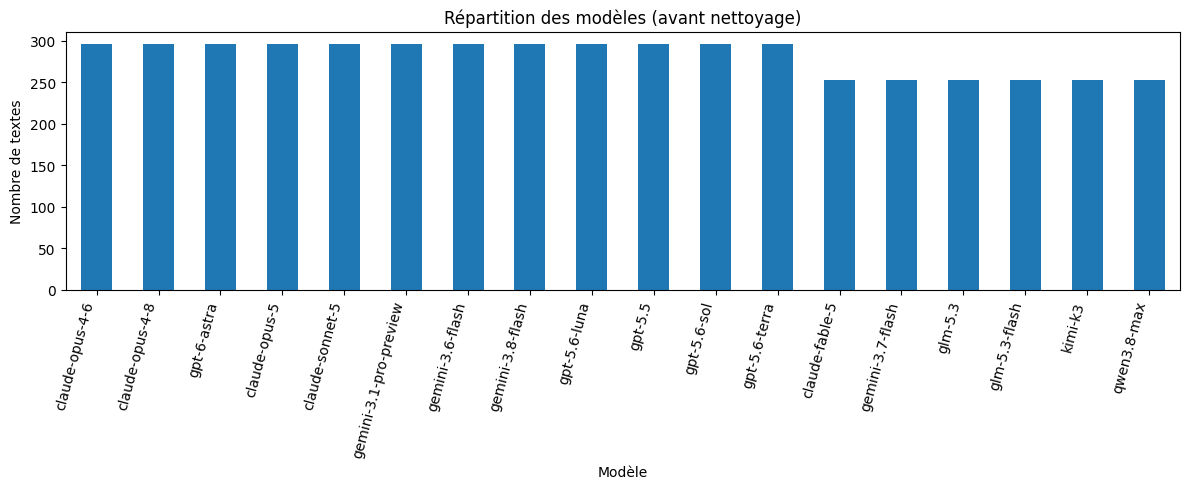

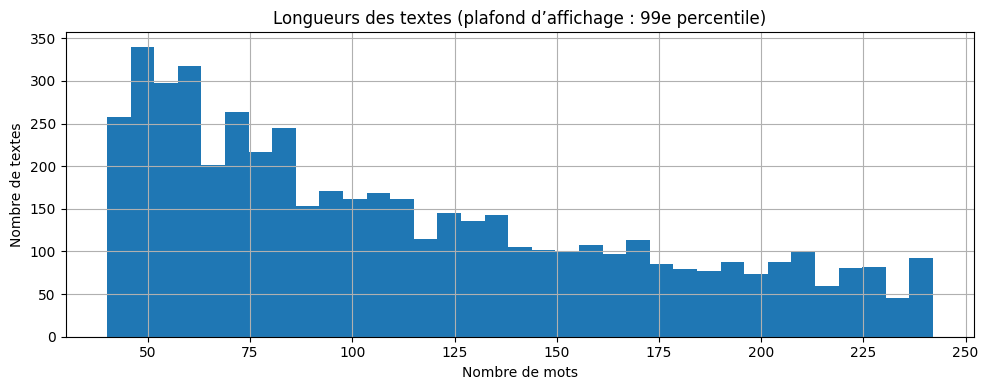

In [36]:
import matplotlib.pyplot as plt

# Je décris la donnée sans la modifier à ce stade.
print('Valeurs manquantes :')
display(df_brut.isna().sum().to_frame('nombre'))
print('Doublons exacts de texte :', df_brut['text'].duplicated().sum())
print('Nombre de classes :', df_brut['model'].nunique(dropna=True))

eda = df_brut.copy()
eda['n_caracteres'] = eda['text'].fillna('').astype(str).str.len()
eda['n_mots'] = eda['text'].fillna('').astype(str).str.split().str.len()
display(eda[['n_caracteres', 'n_mots']].describe())

effectifs = eda['model'].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(12, 5))
effectifs.plot(kind='bar', ax=ax)
ax.set(title='Répartition des modèles (avant nettoyage)', xlabel='Modèle', ylabel='Nombre de textes')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
limite_visuelle = max(1, int(eda['n_mots'].quantile(.99)))
eda['n_mots'].clip(upper=limite_visuelle).hist(bins=35, ax=ax)
ax.set(title='Longueurs des textes (plafond d’affichage : 99e percentile)',
       xlabel='Nombre de mots', ylabel='Nombre de textes')
plt.tight_layout()
plt.show()

## 3.3 PRÉTRAITEMENT — Nettoyage et séparation sans fuite

**Ce que j'ai constaté :** le notebook original traite des textes et groupes de prompts pour l'inférence, mais ne montre pas un protocole pédagogique complet séparant train/validation/test.

**Mes choix :**

- J'enlève les valeurs manquantes et les textes vides, sans supprimer la casse ni la ponctuation.
- Je retire les doublons textuels exacts et les textes identiques associés à plusieurs labels, car ils introduisent une ambiguïté dans une classification déterministe.
- Si `prompt_id` existe et est exploitable, je répartis les **prompts** entre les ensembles : cela évite que le modèle retrouve un même prompt pendant l'apprentissage et la validation.
- Sinon, je réalise un tirage **stratifié** par classe et je **signale la limite** du protocole.

Je réserve environ 70 % au TRAIN, 15 % à la VALIDATION et 15 % au TEST FINAL. Je ne me sers pas du test pour choisir les hyperparamètres.

In [37]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

travail = df_brut.copy()
initial = len(travail)
travail = travail.dropna(subset=['text', 'model']).copy()
travail['text'] = travail['text'].astype(str)
travail['model'] = travail['model'].astype(str)
travail = travail[travail['text'].str.strip().ne('')].copy()

# Un même texte ne doit pas être associé à plusieurs vérités différentes.
contradictions = travail.groupby('text')['model'].nunique()
textes_ambigus = set(contradictions[contradictions > 1].index)
travail = travail[~travail['text'].isin(textes_ambigus)].copy()
travail = travail.drop_duplicates(subset=['text']).reset_index(drop=True)

# dans la cellule de configuration : plafonner les exemples
# par classe uniquement pour maîtriser les ressources Colab.
# L'EDA précédente portait sur le dataset complet ; le modèle est entraîné
# sur ce sous-échantillon, ce que je signalerai dans mon compte rendu.
if MAX_EXEMPLES_PAR_CLASSE is not None:
    morceaux = [g.sample(n=min(len(g), MAX_EXEMPLES_PAR_CLASSE), random_state=SEED)
                for _, g in travail.groupby('model', sort=True)]
    travail = pd.concat(morceaux, ignore_index=True)
    print('Sous-échantillonnage maximal par classe :', MAX_EXEMPLES_PAR_CLASSE)

print('Lignes initiales :', initial, ' ; lignes restantes :', len(travail))
print('Textes contradictoires exclus :', len(textes_ambigus))

if travail['model'].nunique() < 2:
    raise ValueError('Il faut au moins deux classes étiquetées pour une classification.')

utilise_prompts = ('prompt_id' in travail.columns
                   and travail['prompt_id'].notna().all()
                   and travail['prompt_id'].nunique() >= 10)

if utilise_prompts:
    # Je divise par groupes, et non par lignes, pour limiter la fuite liée aux prompts.
    premier = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    idx_train, idx_restant = next(premier.split(travail, groups=travail['prompt_id']))
    restant = travail.iloc[idx_restant]
    second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=43)
    idx_val_local, idx_test_local = next(second.split(restant, groups=restant['prompt_id']))
    train_df = travail.iloc[idx_train].copy()
    val_df = restant.iloc[idx_val_local].copy()
    test_df = restant.iloc[idx_test_local].copy()
    assert set(train_df.prompt_id).isdisjoint(val_df.prompt_id)
    assert set(train_df.prompt_id).isdisjoint(test_df.prompt_id)
    assert set(val_df.prompt_id).isdisjoint(test_df.prompt_id)
    print('Méthode : séparation par prompt_id (GroupShuffleSplit).')
else:
    # Solution de repli à expliciter : je ne peux pas vérifier la généralisation
    # à des prompts inconnus si l'identifiant de prompt est absent.
    if travail['model'].value_counts().min() < 3:
        raise ValueError('Classes trop rares pour la stratification : analyser le dataset avant de poursuivre.')
    train_df, reste = train_test_split(
        travail, test_size=.30, stratify=travail['model'], random_state=42)
    val_df, test_df = train_test_split(
        reste, test_size=.50, stratify=reste['model'], random_state=43)
    print('AVERTISSEMENT : stratification par classe, car prompt_id est absent/inexploitable.')

# Après déduplication avant séparation, aucun texte n'est partagé entre les ensembles.
assert set(train_df.text).isdisjoint(val_df.text)
assert set(train_df.text).isdisjoint(test_df.text)
assert set(val_df.text).isdisjoint(test_df.text)

# Le classificateur ne peut pas apprendre une classe jamais rencontrée en TRAIN.
manquants_train = set(travail['model']) - set(train_df['model'])
if manquants_train:
    raise ValueError(f'Classes absentes de TRAIN : {sorted(manquants_train)}. Adapter le split par groupes.')

for nom, part in [('Train',train_df),('Validation',val_df),('Test',test_df)]:
    print(f'{nom}: {len(part)} textes ; {part.model.nunique()} classes')

Sous-échantillonnage maximal par classe : 250
Lignes initiales : 5070  ; lignes restantes : 4500
Textes contradictoires exclus : 0
Méthode : séparation par prompt_id (GroupShuffleSplit).
Train: 3192 textes ; 18 classes
Validation: 678 textes ; 18 classes
Test: 630 textes ; 18 classes


## 3.4 TRANSFORMATIONS — Quatre vues textuelles du SVC4 original

**Ce qui était déjà présent :** dans `svc4_runtime.py`, l'auteur définit quatre vues du texte, quatre TF-IDF et une concaténation pondérée :

- `char` : n-grammes de caractères, sensibles à la ponctuation et aux motifs courts ;
- `word` : n-grammes de mots, pour le vocabulaire et les tournures ;
- `shape` : structure orthographique transformée en motifs de lettres ;
- `function` : mots-outils conservés, autres mots remplacés par `CONTENT`, pour accentuer des habitudes stylistiques.

**Ce que j'adapte :** je reproduis cette logique (en citant la source) mais **je réalise moi-même le `fit` des quatre vectoriseurs uniquement sur TRAIN**. Je réduis `max_features` par rapport au grand ensemble Kaggle afin de mieux respecter les ressources d'une séance courte. Les poids des quatre vues restent inspirés de l'original.

**Risque que je veux éviter :** ajuster TF-IDF avant le split constituerait une fuite du vocabulaire des données d'évaluation.

In [38]:
import re
import numpy as np
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer

# Adaptation documentée de la cellule originale 10 (svc4_runtime.py).
# La liste des mots fonctionnels et la logique de transformation proviennent du code source.
FUNCTION_WORDS = set("a an the and or but if while although because as so than that which who whom whose this these those it its they them their theirs he him his she her hers we us our ours you your yours i me my mine in on at to from with without for of by over under between through into about is are was were be been being have has had do does did can could will would shall should may might must not no nor all any some each every both either neither other another such only also just very too more most less least here there when where why how what whether then now still yet even much many few little".split())

# (vue, ngram_min, ngram_max, max_features, poids)
# Je réduis les plafonds originaux (250k/180k/60k/50k) pour les ressources disponibles.
VUES = [
    ('char', 3, 5, 40000, 1.0),
    ('word', 1, 3, 30000, 0.7),
    ('shape', 2, 6, 15000, 0.5),
    ('function', 1, 3, 12000, 0.5),
]


def preparer_vue(nom_vue, texte):
    texte = str(texte)
    if nom_vue == 'shape':
        return re.sub(r"[^\W\d_]+", lambda m: 'X' if m[0].isupper() else 'x', texte)
    if nom_vue == 'function':
        return ' '.join(mot.lower() if mot.lower() in FUNCTION_WORDS or not mot.isalnum()
                        else 'CONTENT' for mot in re.findall(r'\w+|[^\w\s]', texte))
    return texte


def options_vectoriseur(spec):
    vue, debut, fin, maximum, _ = spec
    analyseur = 'char' if vue == 'shape' else 'word' if vue == 'function' else vue
    params = dict(analyzer=analyseur, ngram_range=(debut, fin), lowercase=False,
                  sublinear_tf=True, min_df=2, max_features=maximum, dtype=np.float32)
    if analyseur == 'word':
        params['token_pattern'] = r'(?u)\b\w+\b|[^\w\s]'
    return params

# Je conserve les vecteurs entraînés et les coefficients, pour l'inférence future.
vectoriseurs = {}
blocs_train, blocs_val, blocs_test = [], [], []
for spec in VUES:
    nom, *_milieu, poids = spec
    vecteur = TfidfVectorizer(**options_vectoriseur(spec))
    t_train = [preparer_vue(nom, t) for t in train_df['text']]
    t_val = [preparer_vue(nom, t) for t in val_df['text']]
    t_test = [preparer_vue(nom, t) for t in test_df['text']]
    x_tr = vecteur.fit_transform(t_train)  # Je n'ajuste rien sur validation/test.
    blocs_train.append(x_tr * poids)
    blocs_val.append(vecteur.transform(t_val) * poids)
    blocs_test.append(vecteur.transform(t_test) * poids)
    vectoriseurs[nom] = vecteur
    print(f'Vue {nom:<9}: {x_tr.shape[1]:,} caractéristiques')

X_train = hstack(blocs_train, format='csr')
X_val = hstack(blocs_val, format='csr')
X_test = hstack(blocs_test, format='csr')
print('Matrice d’entraînement :', X_train.shape, '; nnz =', X_train.nnz)

Vue char     : 40,000 caractéristiques
Vue word     : 30,000 caractéristiques
Vue shape    : 6,816 caractéristiques
Vue function : 12,000 caractéristiques
Matrice d’entraînement : (3192, 88816) ; nnz = 6192056


## 3.5 ML — Entraînement effectif de la branche SVC4

**Manquement constaté :** le notebook original charge les vectoriseurs et les paramètres du `LinearSVC` déjà entraînés ; je n'y observe pas, dans l'exécution de soumission, de cellule qui réalise cet entraînement.

**Ce que j'ajoute :** un `fit()` sur TRAIN avec les quatre vues précédentes et un **classificateur naïf de référence** entraîné uniquement sur les labels. Ce dernier me permettra de vérifier que mon modèle apporte réellement quelque chose au-delà de la classe majoritaire.

**Justification :** je reprends les réglages visibles de la branche SVC4 (`C=0.5`, `class_weight='balanced'`, `max_iter=5000`, `random_state=42`) plutôt que d'inventer un nouvel algorithme. Je conserve un jeu VAL pour l'évaluation et ne touche pas au TEST FINAL avant d'avoir terminé mes choix.

In [39]:
import time
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier

classes_train = train_df['model'].to_numpy()
classes_val = val_df['model'].to_numpy()
classes_test = test_df['model'].to_numpy()

naif = DummyClassifier(strategy='most_frequent')
naif.fit(X_train, classes_train)

modele_svc4 = LinearSVC(C=0.5, class_weight='balanced', random_state=42, max_iter=5000)
debut = time.perf_counter()
modele_svc4.fit(X_train, classes_train)
duree_ml = time.perf_counter() - debut
print(f'LinearSVC entraîné en {duree_ml:.2f} secondes')
print('Classes apprises :', len(modele_svc4.classes_))

LinearSVC entraîné en 17.53 secondes
Classes apprises : 18


## 3.6 EVAL — Validation, test et analyse des erreurs

**Manquement du notebook original :** il produit des prédictions et contrôle des formats, mais le `test.csv` de compétition n'a pas de vérité terrain permettant de calculer mes métriques. Les calibrations de folds fournies ne constituent pas un nouveau protocole de validation affiché dans ce notebook.

**Ce que j'ajoute :** une **balanced accuracy**, une accuracy, un **F1-macro**, un rapport par classe et une **matrice de confusion**.

**Pourquoi :** les modèles peuvent avoir des effectifs inégaux. Une bonne accuracy globale peut masquer une mauvaise reconnaissance des classes minoritaires. Je compare la baseline naïve et SVC4 sur VAL, puis je réserve le TEST pour un résultat final indépendant.

**Prudence :** ces résultats ne sont **pas directement comparables au 0.681 Kaggle**, car l'architecture, la source des données et la méthode d'évaluation diffèrent.

VALIDATION :


,Classe majoritaire,SVC4 adapté
accuracy,0.054572,0.328909
balanced_accuracy,0.055556,0.329676
f1_macro,0.005750,0.311619


TEST FINAL (modèle figé) : {'accuracy': 0.32222222222222224, 'balanced_accuracy': 0.3222222222222222, 'f1_macro': 0.30260813966418787}

Rapport par classe :
                        precision    recall  f1-score   support

        claude-fable-5       0.07      0.06      0.06        35
       claude-opus-4-6       0.40      0.46      0.43        35
       claude-opus-4-8       0.15      0.09      0.11        35
         claude-opus-5       0.38      0.43      0.40        35
       claude-sonnet-5       0.33      0.43      0.37        35
gemini-3.1-pro-preview       0.49      0.80      0.61        35
      gemini-3.6-flash       0.30      0.29      0.29        35
      gemini-3.7-flash       0.40      0.40      0.40        35
      gemini-3.8-flash       0.22      0.17      0.19        35
               glm-5.3       0.17      0.14      0.16        35
         glm-5.3-flash       0.26      0.29      0.27        35
               gpt-5.5       0.41      0.40      0.41        35
          

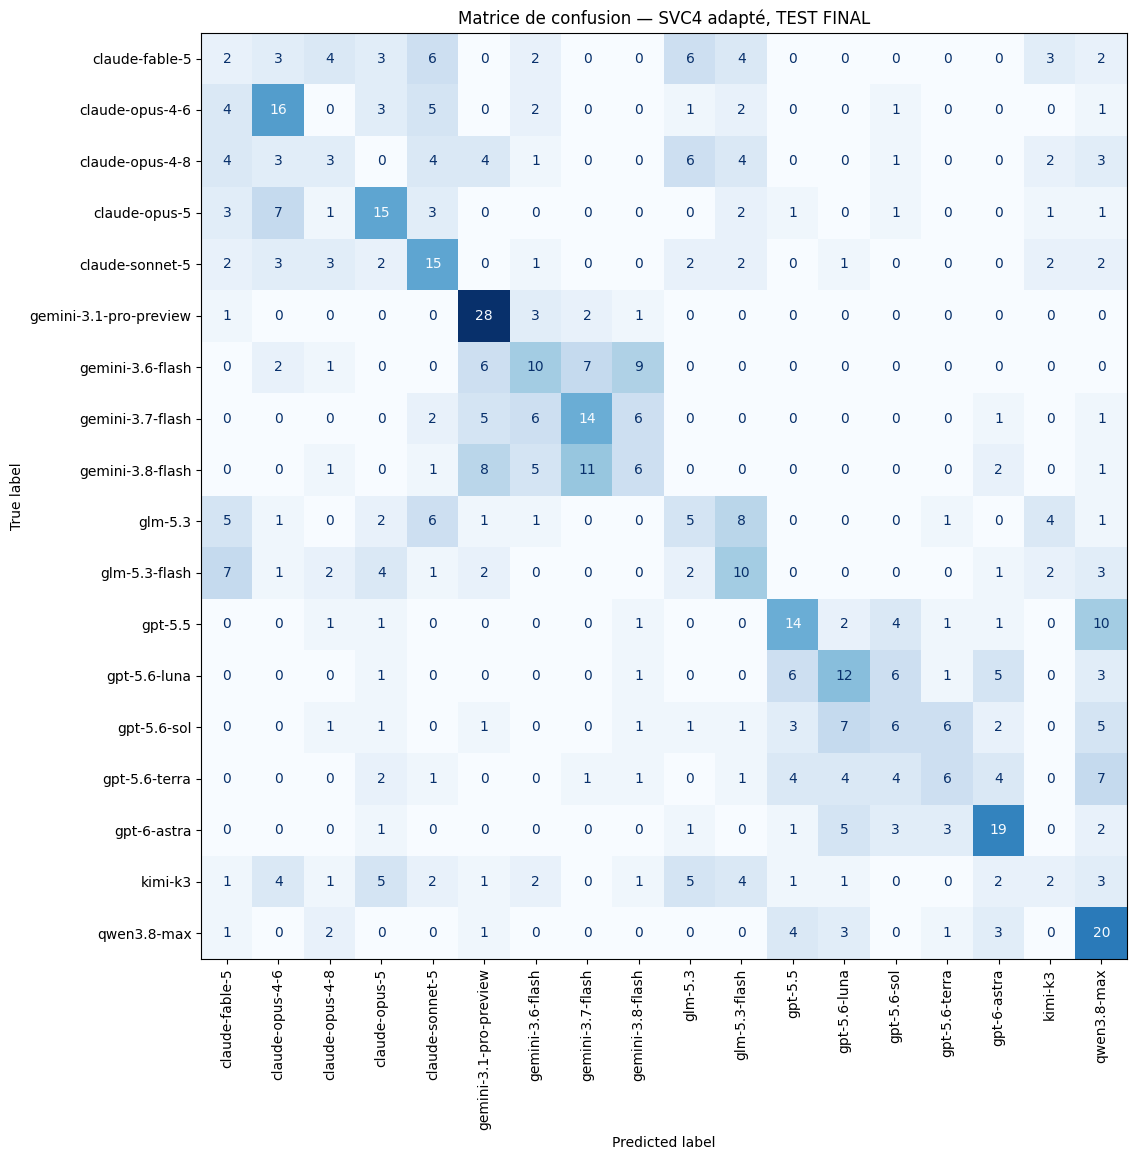


Mon analyse :
La balanced accuracy sur le test final est de 0.322 et le F1-macro de 0.303.
Sur VALIDATION, SVC4 dépasse la prédiction systématique de la classe majoritaire.
Je dois maintenant décrire les confusions visibles dans la matrice, sans surinterpréter ces scores.


In [40]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt


def evaluer(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'f1_macro': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }

val_naive = evaluer(classes_val, naif.predict(X_val))
val_svc4 = evaluer(classes_val, modele_svc4.predict(X_val))
print('VALIDATION :')
display(pd.DataFrame({'Classe majoritaire': val_naive, 'SVC4 adapté': val_svc4}))

# Je n'utilise pas TEST pour régler les hyperparamètres.
pred_test = modele_svc4.predict(X_test)
metriques_test = evaluer(classes_test, pred_test)
print('TEST FINAL (modèle figé) :', metriques_test)
print('\nRapport par classe :')
print(classification_report(classes_test, pred_test, zero_division=0))

labels_affiches = sorted(set(classes_test) | set(pred_test))
fig, ax = plt.subplots(figsize=(max(8, len(labels_affiches)*0.7),
                                max(7, len(labels_affiches)*0.65)))
ConfusionMatrixDisplay.from_predictions(
    classes_test, pred_test, labels=labels_affiches, xticks_rotation=90,
    cmap='Blues', colorbar=False, ax=ax, values_format='d')
ax.set_title('Matrice de confusion — SVC4 adapté, TEST FINAL')
plt.tight_layout()
plt.show()

# Commentaire automatique basé sur les scores, sans résultat inventé.
print('\nMon analyse :')
print('La balanced accuracy sur le test final est de '
      f"{metriques_test['balanced_accuracy']:.3f} et le F1-macro de {metriques_test['f1_macro']:.3f}.")
if val_svc4['balanced_accuracy'] > val_naive['balanced_accuracy']:
    print('Sur VALIDATION, SVC4 dépasse la prédiction systématique de la classe majoritaire.')
else:
    print('Sur VALIDATION, SVC4 ne dépasse pas la référence naïve : je dois examiner les erreurs.')
print('Je dois maintenant décrire les confusions visibles dans la matrice, sans surinterpréter ces scores.')

In [41]:

# Récapitulatif des performances obtenues

resultats = pd.DataFrame(
    [val_naive, val_svc4, metriques_test],
    index=[
        "Baseline - Validation",
        "SVC4 - Validation",
        "SVC4 - Test final"
    ]
)

display(resultats.round(4))

print("\nDifférence de balanced accuracy :")
print(
    round(
        val_svc4["balanced_accuracy"]
        - val_naive["balanced_accuracy"],
        4
    )
)


,accuracy,balanced_accuracy,f1_macro
Baseline - Validation,0.0546,0.0556,0.0057
SVC4 - Validation,0.3289,0.3297,0.3116
SVC4 - Test final,0.3222,0.3222,0.3026



Différence de balanced accuracy :
0.2741


## 3.7 DEPLOY — Réutiliser le modèle entraîné

**Manquement du notebook original :** l'export `submission.parquet` n'est pas une interface permettant de saisir un nouveau texte.

**Amélioration :** je sauvegarde les **quatre vectoriseurs et le LinearSVC** ensemble avec `joblib`, puis je teste le rechargement. Je démontre le chargement et la prédiction dans Colab, puis une interface Gradio locale facultative. La prédiction réutilise exactement les mêmes transformations `char/word/shape/function`.

**Pourquoi :** si je sauvegardais uniquement le classificateur, je perdrais le vocabulaire et les poids TF-IDF appris pendant l'entraînement. Un nouvel appel d'inférence ne serait plus cohérent avec TRAIN.

**Honnêteté expérimentale :** ceci constitue un **prototype de déploiement local** ; générer `app.py` ne prouve pas que l'application soit accessible publiquement. L'interface affiche une **classe prédite**, pas une probabilité certifiée (les marges de `LinearSVC` ne sont pas des probabilités calibrées).

In [42]:
from pathlib import Path
import joblib

sortie_adaptee = DOSSIER_SORTIES
sortie_adaptee.mkdir(parents=True, exist_ok=True)
modele_path = sortie_adaptee / 'svc4_adapte.joblib'

bundle = {'vectoriseurs': vectoriseurs, 'modele': modele_svc4, 'vues': VUES,
          'provenance': str(chemin_data), 'methode': 'SVC4 adapté de lightningv08'}
joblib.dump(bundle, modele_path)


def predictions_rechargees(textes, chemin=modele_path):
    # Chargement uniquement d'un artefact que j'ai moi-même produit et auquel je fais confiance.
    charge = joblib.load(chemin)
    blocs = []
    for vue, _, _, _, poids in charge['vues']:
        textes_vue = [preparer_vue(vue, t) for t in textes]
        blocs.append(charge['vectoriseurs'][vue].transform(textes_vue) * poids)
    vecteurs = hstack(blocs, format='csr')
    return charge['modele'].predict(vecteurs)

# Je teste que le modèle sauvegardé reste cohérent après rechargement.
exemples_test = test_df['text'].iloc[:min(3, len(test_df))].tolist()
assert list(predictions_rechargees(exemples_test)) == list(modele_svc4.predict(X_test[:len(exemples_test)]))
print('Modèle sauvegardé :', modele_path)
print('Test de rechargement : OK')
print('Prédictions sur des exemples réservés :', predictions_rechargees(exemples_test).tolist())

Modèle sauvegardé : /content/name_that_llm/sorties/svc4_adapte.joblib
Test de rechargement : OK
Prédictions sur des exemples réservés : ['gemini-3.6-flash', 'kimi-k3', 'claude-opus-4-6']


In [43]:
# DEPLOY — Mon interface de démonstration fonctionne dans le notebook Colab.
# Elle appelle bien les mêmes objets sauvegardés que le modèle validé.
import gradio as gr

# mettre True pour ouvrir l'application dans Colab.
LANCER_INTERFACE = True


def predire_modele(texte):
    if not str(texte).strip():
        return 'Veuillez saisir un texte.'
    return str(predictions_rechargees([str(texte)])[0])

interface = gr.Interface(
    fn=predire_modele,
    inputs=gr.Textbox(lines=6, label='Texte à analyser'),
    outputs=gr.Textbox(label='Modèle prédit'),
    title='Name That LLM — SVC4 adapté',
    description='Prototype éducatif : attribution statistique, et non preuve certaine de provenance.'
)
print('Fonction d’inférence prête. Exemple :', predire_modele(test_df['text'].iloc[0]))
if LANCER_INTERFACE:
    interface.launch(share=False, inline=True, prevent_thread_lock=True)
else:
    print('Interface préparée, non ouverte. Pour la tester, mettre LANCER_INTERFACE = True.')


Fonction d’inférence prête. Exemple : gemini-3.6-flash
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## Bilan de mes modifications (à compléter avec les scores observés)

| Étape | État avant adaptation | Ce que j'ai ajouté / adapté | Justification |
|---|---|---|---|
| DATA | Chemins et lectures essentiellement liés à l'inférence | Chargement contrôlé d'un CSV **étiqueté** | Maîtriser la provenance, le schéma et la cible `model` |
| EDA | Pas d'analyse dédiée | Répartition par modèle, longueurs, doublons et manquants | Identifier les biais et problèmes de qualité |
| PRÉTRAITEMENT | Routines dispersées, pas de split pédagogique | Nettoyage conservateur et split par `prompt_id` si possible | Éviter les fuites et garder les marqueurs de style |
| TRANSFORMATIONS | Multiples représentations complexes | Réentraînement de **quatre TF-IDF SVC4** | Garder la logique existante et assurer la reproductibilité |
| ML | Poids souvent préajustés, inférence | `LinearSVC.fit` + baseline naïve | Montrer un apprentissage effectif sur TRAIN |
| EVAL | Soumission et contrôles de format | Balanced accuracy, F1-macro et matrice de confusion | Mesurer la généralisation sur labels réservés |
| DEPLOY | `submission.parquet` | Modèle sérialisé, test de rechargement et script Streamlit | Permettre une prédiction sur un texte inédit |

### Interprétation personnelle à écrire après l'exécution

- **Résultat de l'original :** `[...]` (noter s'il s'agit du mode preview, du mode complet ou d'un échec lié aux dépendances).
- **Résultat du SVC4 adapté sur VALIDATION :** `[...]` et différence par rapport au classificateur naïf `[...]`.
- **Résultat du SVC4 adapté sur TEST :** `[...]` ; principales confusions observées `[...]`.
- **Coût de calcul / environnement :** `[...]`.
- **Limites de comparaison :** je ne compare pas directement les métriques de cette adaptation à un score de compétition calculé sur un autre protocole.

### Pistes d'amélioration

Je pourrais vérifier les variations de `max_features`, les n-grammes et `C` uniquement sur VALIDATION. Avec davantage de ressources GPU, je pourrais comparer cette branche SVC4 aux embeddings Qwen3, puis mesurer leur complémentarité, comme le fait le notebook original. Je garderais le TEST FINAL isolé jusqu'à ce que les choix soient arrêtés.

**Source et crédit :** lightningv08, [notebook de référence](https://www.kaggle.com/code/lightningv08/0-681-qwen3-embedding-lora-qwen3-8-27b/notebook), ainsi que les auteurs mentionnés dans son introduction. Le code original appartient à ses auteurs ; les cellules d'audit, d'adaptation et de validation constituent mon propre travail de compréhension et de modification.

# PARTIE 4 — Bilan final et points à compléter avant le rendu

## Ce que j'ai amélioré par rapport au notebook original

- **DATA :** les chemins ne dépendent plus du runtime Kaggle ; j'utilise KaggleHub dans Colab, une vérification de schéma et une source étiquetée.
- **EDA :** j'affiche effectifs par LLM, longueurs, valeurs manquantes et doublons.
- **PRÉTRAITEMENT :** je documente le nettoyage conservateur et le découpage train/validation/test, idéalement par `prompt_id`.
- **TRANSFORMATIONS :** je réutilise les quatre représentations de **SVC4**, en ajustant les TF-IDF uniquement sur TRAIN pour éviter une fuite de données.
- **ML :** j'entraîne explicitement un `LinearSVC` et un classificateur naïf de référence.
- **EVAL :** je calcule balanced accuracy, F1-macro, matrice de confusion et rapport par classe sur des textes jamais utilisés pour l'apprentissage.
- **DEPLOY :** je sérialise les vectoriseurs + le modèle, puis je les recharge pour réaliser une prédiction et préparer une interface Gradio dans Colab.

### après exécution réelle

**Résultat du notebook d'origine :** `[indiquer le mode observé et les blocages concrets]`  
**Dataset finalement utilisé :** `[chemin, lignes, classes, présence de prompt_id]`  
**Score de validation de ma branche SVC4 :** `[balanced accuracy, F1-macro]`  
**Score de test indépendant :** `[balanced accuracy, F1-macro]`  
**Principales erreurs :** `[classes confondues, éventuel déséquilibre]`  
**Limites :** `Ce modèle léger n'est pas directement comparable à l'ensemble Qwen3 du notebook source.`

Je n'inscris **aucun score avant exécution**. Mon apport est d'avoir rendu vérifiables toutes les étapes de la chaîne, pas de revendiquer les performances du notebook original.

### Avant de rendre le devoir

- Exécuter les cellules **jusqu'à cette section**, dans l'ordre ; renseigner les chemins uniquement dans les cellules.
- Vérifier que les sorties et figures correspondent réellement aux données téléchargées, et rédiger mes observations personnelles.
- Conserver l'**annexe de code original** pour prouver le point de départ et permettre l'inspection des cellules de lightningv08.
- **Ne pas cliquer sur « Tout exécuter »** pour l'ensemble du fichier, car l'annexe suivante exige les checkpoints GPU qui n'ont pas été téléchargés.

**Sources :** [notebook de lightningv08](https://www.kaggle.com/code/lightningv08/0-681-qwen3-embedding-lora-qwen3-8-27b/notebook) · [dataset étendu prvsiyan](https://www.kaggle.com/datasets/prvsiyan/prvsiyans-extended-name-that-llm-dataset) · [jeu officiel de compétition](https://www.kaggle.com/competitions/name-that-llm/data) · [documentation KaggleHub](https://github.com/Kaggle/kagglehub).